In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ipywidgets
import os

In [3]:
import kagglehub
kagglehub.login()

In [4]:
# Download latest version
path = kagglehub.competition_download('house-prices-advanced-regression-techniques')

print("Path to competition files:", path)

Path to competition files: C:\Users\Admin\.cache\kagglehub\competitions\house-prices-advanced-regression-techniques


In [ ]:
# my initial idea of which columns will have the strongest correlation to sale price
train_df = pd.read_csv(os.path.join(path, 'train.csv'))
gr_liv_area = train_df["GrLivArea"].to_numpy()
garage_area = train_df["GarageArea"].to_numpy()
year_built = train_df["YearBuilt"].to_numpy()
year_remodelled = train_df["YearRemodAdd"].to_numpy()
year_sold = train_df["YrSold"].to_numpy()
overall_qual = train_df["OverallQual"].to_numpy()
overall_cond = train_df["OverallCond"].to_numpy()
neighborhood = train_df["Neighborhood"].to_numpy()
sale_price = train_df["SalePrice"].to_numpy()

In [6]:
# check the correlation between each column and sale price
train_df.select_dtypes('number').corr()['SalePrice'].sort_values(ascending=False)
# added garage_area from this

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

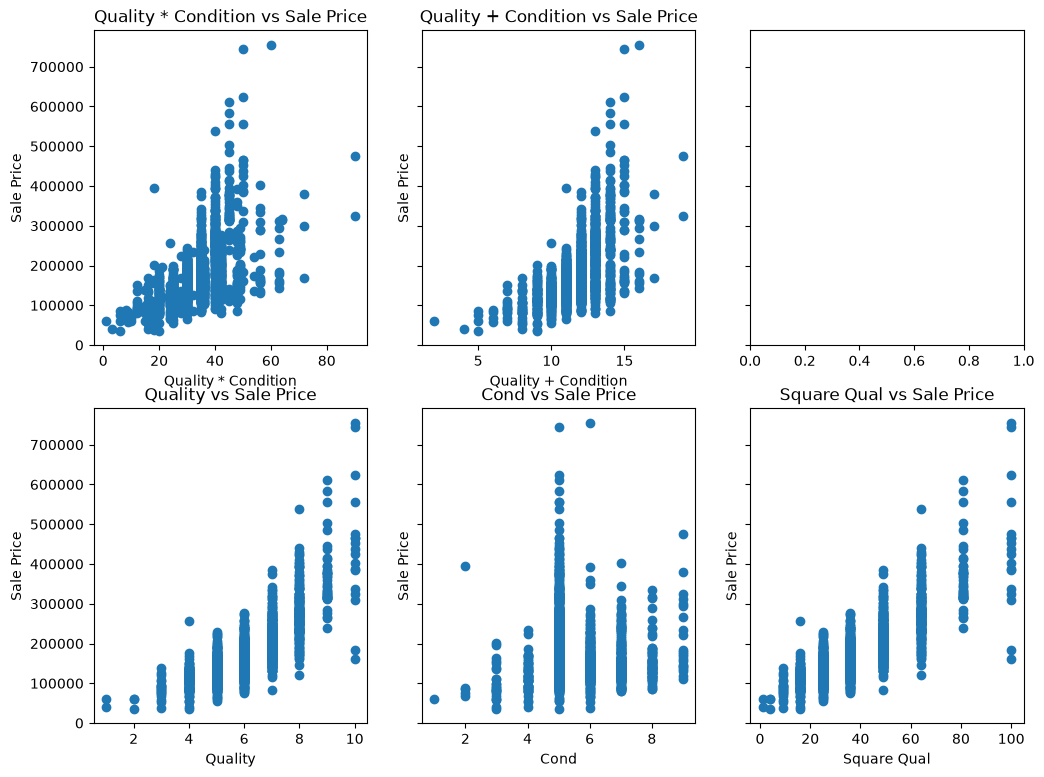

In [7]:
mult_qual_cond = overall_qual * overall_cond
add_qual_cond = overall_qual + overall_cond
square_qual = overall_qual ** 2

fig, axes = plt.subplots(2, 3, figsize=(12,9), sharey=True)

axes[0,0].scatter(mult_qual_cond, sale_price)
axes[0,0].set_title("Quality * Condition vs Sale Price")
axes[0,0].set_xlabel("Quality * Condition")
axes[0,0].set_ylabel("Sale Price")

axes[0,1].scatter(add_qual_cond, sale_price)
axes[0,1].set_title("Quality + Condition vs Sale Price")
axes[0,1].set_xlabel("Quality + Condition")
axes[0,1].set_ylabel("Sale Price")

axes[1,0].scatter(overall_qual, sale_price)
axes[1,0].set_title("Quality vs Sale Price")
axes[1,0].set_xlabel("Quality")
axes[1,0].set_ylabel("Sale Price")

axes[1,1].scatter(overall_cond, sale_price)
axes[1,1].set_title("Cond vs Sale Price")
axes[1,1].set_xlabel("Cond")
axes[1,1].set_ylabel("Sale Price")

axes[1,2].scatter(square_qual, sale_price)
axes[1,2].set_title("Square Qual vs Sale Price")
axes[1,2].set_xlabel("Square Qual")
axes[1,2].set_ylabel("Sale Price")
plt.show()

In [16]:
for p in range(1, 5):
    print((overall_qual ** p).corr(sale_price))

0.7909816005838054
0.8171684436128851
0.825237796790755
0.8190695088085753


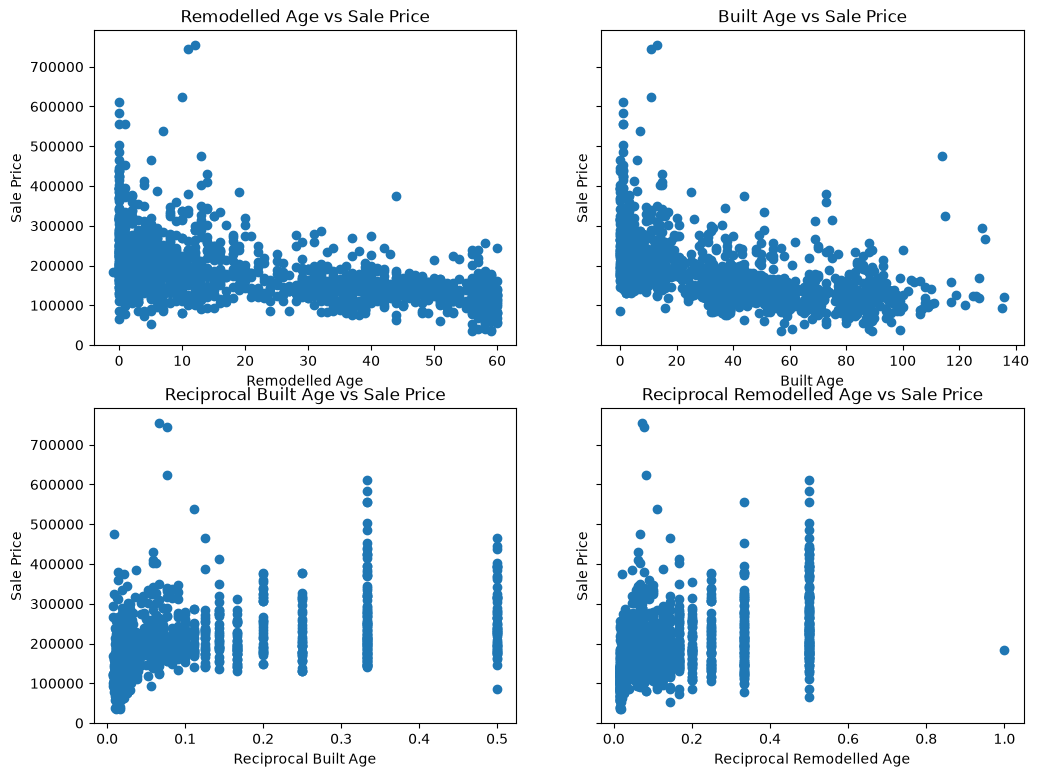

In [25]:
year_built = train_df["YearBuilt"]
year_remodelled = train_df["YearRemodAdd"]
year_sold = train_df["YrSold"]

year_built_arr = year_built.to_numpy()
year_remodelled_arr = year_remodelled.to_numpy()
year_sold_arr = year_sold.to_numpy()
# looks like 1/x

remodelled_age = year_sold_arr - year_remodelled_arr
built_age = year_sold_arr - year_built_arr
# try 1/x

reciprocal_built_age = 1 / (built_age + 2)
reciprocal_remodelled_age = 1 / (remodelled_age + 2)

fig, axes = plt.subplots(2, 2, figsize=(12,9), sharey=True)

axes[0,0].scatter(remodelled_age, sale_price)
axes[0,0].set_title("Remodelled Age vs Sale Price")
axes[0,0].set_xlabel("Remodelled Age")
axes[0,0].set_ylabel("Sale Price")

axes[0,1].scatter(built_age, sale_price)
axes[0,1].set_title("Built Age vs Sale Price")
axes[0,1].set_xlabel("Built Age")
axes[0,1].set_ylabel("Sale Price")

axes[1,0].scatter(reciprocal_built_age, sale_price)
axes[1,0].set_title("Reciprocal Built Age vs Sale Price")
axes[1,0].set_xlabel("Reciprocal Built Age")
axes[1,0].set_ylabel("Sale Price")

axes[1,1].scatter(reciprocal_remodelled_age, sale_price)
axes[1,1].set_title("Reciprocal Remodelled Age vs Sale Price")
axes[1,1].set_xlabel("Reciprocal Remodelled Age")
axes[1,1].set_ylabel("Sale Price")

plt.show()

In [ ]:
train_df["YearRemodAdd"].value_counts().sort_index().head(10)

# floor for remodelled date at 1950

YearRemodAdd
1950    178
1951      4
1952      5
1953     10
1954     14
1955      9
1956     10
1957      9
1958     15
1959     18
Name: count, dtype: int64

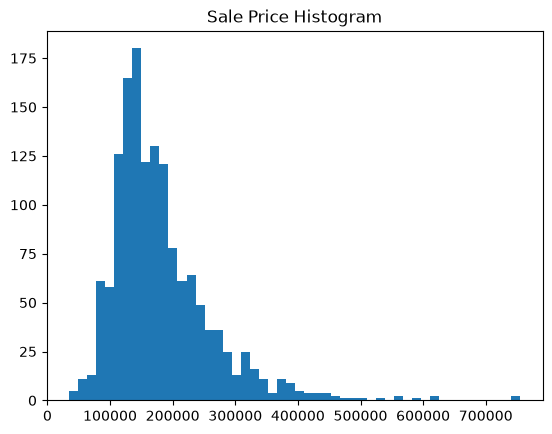

In [ ]:
# its not 1/x but maybe its because the sale price fans out for new houses

plt.hist(sale_price, bins=50)
plt.title("Sale Price Histogram")
plt.show()

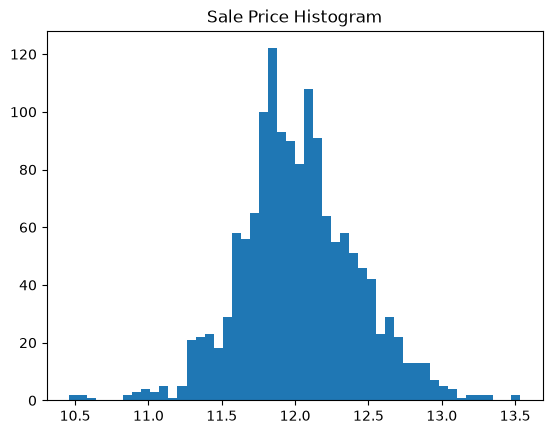

In [ ]:
plt.hist(np.log(sale_price), bins=50)
plt.title("Sale Price Histogram")
plt.show()

Text(0.5, 0, 'Overall Quality Squared')

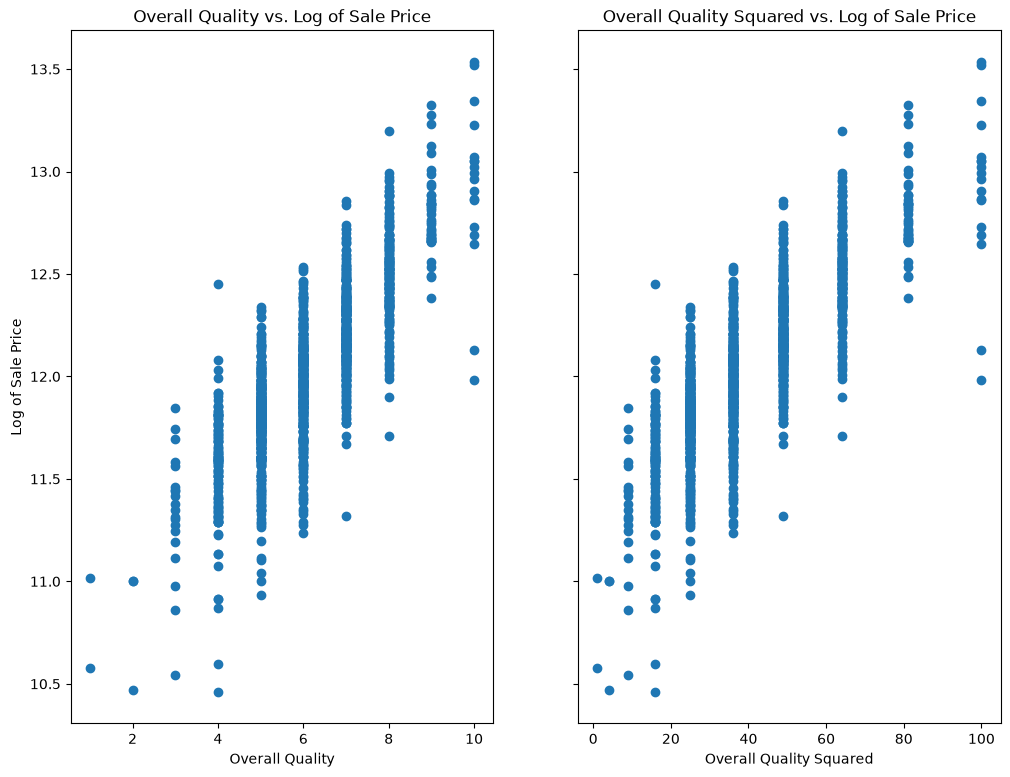

In [ ]:
# re examine our previous feature for our changed target

fig, axes = plt.subplots(1, 2, figsize=(12,9), sharey=True)

axes[0].scatter(overall_qual, np.log(sale_price))
axes[0].set_title("Overall Quality vs. Log of Sale Price")
axes[0].set_xlabel("Overall Quality")
axes[0].set_ylabel("Log of Sale Price")
axes[1].scatter(square_qual, np.log(sale_price))
axes[1].set_title("Overall Quality Squared vs. Log of Sale Price")
axes[1].set_xlabel("Overall Quality Squared")


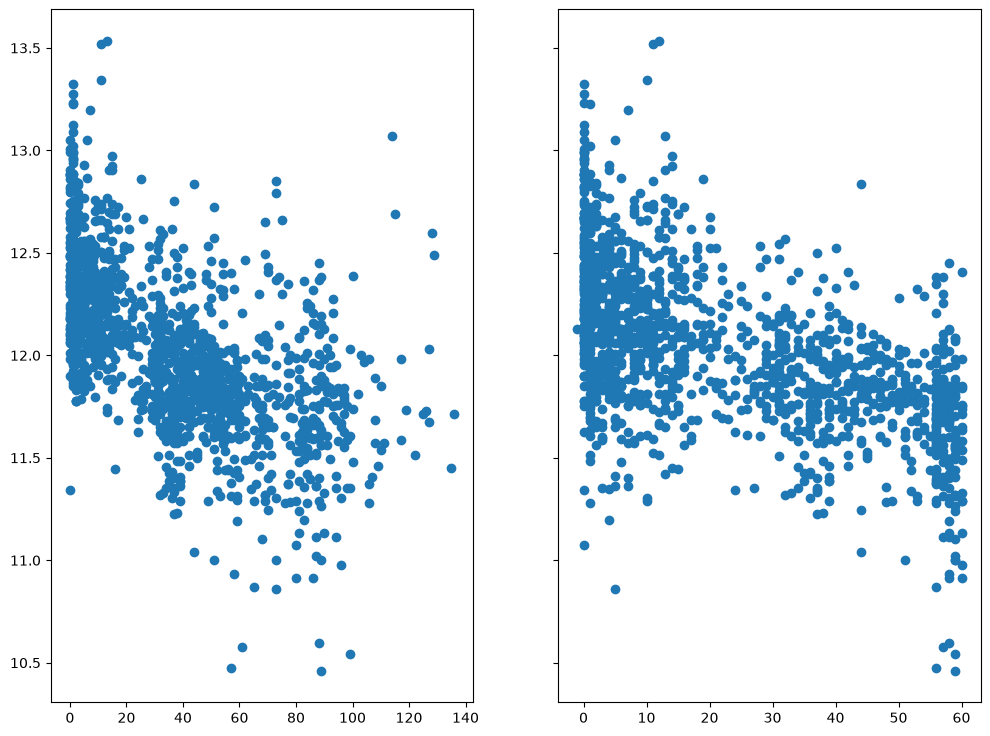

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12,9), sharey=True)

axes[0].scatter(built_age, np.log(sale_price))
axes[1].scatter(remodelled_age, np.log(sale_price))

# looks like remodelled age is more reliable but theres still the issue of the floor -> add
# a flag to let the model adjust to this

remod_floor_flag = np.zeros(remodelled_age.size)
remod_floor_flag[year_remodelled_arr == 1950] = 1

Text(0.5, 0, 'Garage Area')

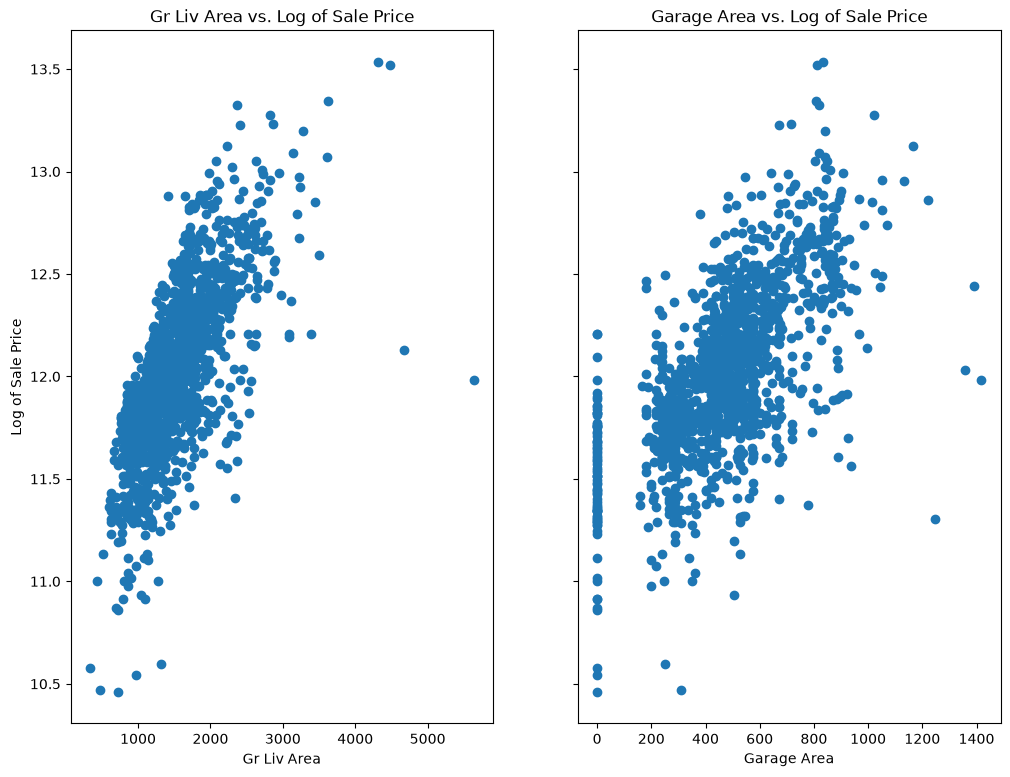

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12,9), sharey=True)

axes[0].scatter(gr_liv_area, np.log(sale_price))
axes[0].set_title("Gr Liv Area vs. Log of Sale Price")
axes[0].set_xlabel("Gr Liv Area")
axes[0].set_ylabel("Log of Sale Price")
axes[1].scatter(garage_area, np.log(sale_price))
axes[1].set_title("Garage Area vs. Log of Sale Price")
axes[1].set_xlabel("Garage Area")

In [ ]:
# want to see if neighborhood affects price and do it by using one-hot encoding

neighborhood_names = np.unique(neighborhood)
neighborhood_names = neighborhood_names[neighborhood_names != "NAmes"]
neighborhood_one_hot = {}
for name in neighborhood_names:
    neighborhood_one_hot[name] = (neighborhood == name).astype(float)

In [33]:
# form training matrix
train_arr = np.column_stack((gr_liv_area, garage_area, overall_qual, built_age, remodelled_age, remod_floor_flag))

for n in neighborhood_one_hot:
    train_arr = np.column_stack((train_arr, neighborhood_one_hot[n]))

In [ ]:
def zscore_normalize_features()